# Pre-entrega 6 · Demo del flujo de delegación

Este notebook muestra el orquestador multi-agente resolviendo una consulta que necesita **dos especialistas** y una **síntesis final**:

1. el **Supervisor** decide a quién delegar;
2. el **Investigador** busca las reglas en el manual del ERP (Pinecone, pre-entrega 4);
3. el **Analista** hace los cálculos con herramientas;
4. el Supervisor valida con su rúbrica y, si todo está completo, el **Sintetizador** redacta la respuesta.

> Requiere el `.env` con las keys de Anthropic, OpenAI (embeddings) y Pinecone. Ver el README.

In [1]:
import json
from IPython.display import Image, Markdown, display

import config
from graph import build_graph
from runner import PREGUNTA_DEMO, ejecutar, guardar

print(f"LLM: {config.LLM_PROVIDER} · base de conocimiento: {config.RESEARCH_BACKEND} · "
      f"tope de delegaciones: {config.MAX_DELEGACIONES} · revisiones por especialista: {config.MAX_REVISIONES}")

LLM: anthropic · base de conocimiento: pinecone · tope de delegaciones: 6 · revisiones por especialista: 2


## 1. El grafo

Topología jerárquica: todos los especialistas reportan al supervisor, y solo el supervisor decide el siguiente paso (líneas punteadas = aristas condicionales).

23:23:23 | INFO    | conocimiento | Base de conocimiento: PineconeKB


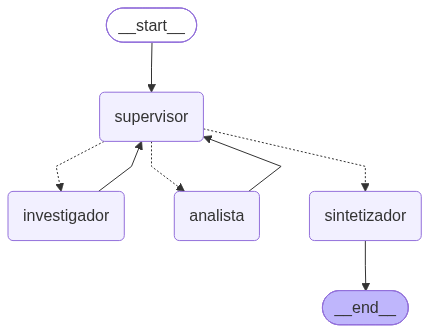

In [2]:
graph = build_graph()
try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:  # sin acceso a mermaid.ink: se muestra el código Mermaid
    print(graph.get_graph().draw_mermaid())

## 2. La consulta

Necesita **investigar** (validez de un presupuesto, seña de muebles a medida, quién aprueba descuentos) y después **calcular** (días transcurridos, precio con descuento, monto de la seña).

In [3]:
print(PREGUNTA_DEMO)

Hoy es 10/11/2026. Un cliente pidió el 28/10/2026 un presupuesto por una biblioteca a medida de $1.180.000 y quiere confirmarlo con un 18 % de descuento. Según el manual del ERP: ¿el presupuesto sigue vigente?, ¿cuánto queda el precio con el descuento y cuánto tiene que pagar de seña?, ¿qué rol puede aprobar ese descuento?


## 3. Ejecución paso a paso

Cada bloque es un nodo del grafo: las decisiones del supervisor y lo que aporta cada especialista.

In [4]:
traza = await ejecutar(graph, PREGUNTA_DEMO)

23:23:25 | INFO    | supervisor | ronda 1 → investigador (llm) · No hay contribuciones todavía, así que hacen falta primero las reglas de negocio con sus fuentes antes de cualquier cálculo.


[SUPERVISOR · ronda 1] → investigador (llm): No hay contribuciones todavía, así que hacen falta primero las reglas de negocio con sus fuentes antes de cualquier cálculo.
    instrucción: Buscá en el manual técnico del ERP: (1) el plazo de vigencia de un presupuesto a medida y si su vencimiento se cuenta en días corridos o hábiles; (2) el porcentaje de seña requerido para confirmar un pedido de mueble a medida; (3) qué roles pueden aprobar un descuento y hasta qué porcentaje, especialmente para descuentos del 18 %. Citá la sección o página de cada regla.



23:23:34 | INFO    | investigador | ronda 1 · 4 búsquedas · fuentes: ['02-autenticacion-y-roles.md', '03-api-ventas.md', '04-integracion-afip.pdf', '05-caja-y-bancos.md', '06-inventario.md', '07-integracion-tiendanube.md', '08-codigos-de-error.json']


[INVESTIGADOR] herramientas: buscar_manual, buscar_manual, buscar_manual, buscar_manual · fuentes: 02-autenticacion-y-roles.md, 03-api-ventas.md, 04-integracion-afip.pdf, 05-caja-y-bancos.md, 06-inventario.md, 07-integracion-tiendanube.md, 08-codigos-de-error.json
    Hallazgos del manual (4 búsquedas realizadas):
    
    **(1) Vigencia del presupuesto**
    - "Crea un presupuesto. Validez: 15 días corridos" [03-api-ventas.md, sección "Endpoints principales"].
    - "El presupuesto venció (pasaron más de 15 días)" [03-api-ventas.md, sección "Errores de la API de ventas", código VTA-410-PRES; también 08-codigos-de-error.json].
    - Sobre si el vencimiento se cuenta en días hábiles: el manual solo dice "corridos"; no hay regla de días hábiles para presupuestos.
    
    **(2) Seña para mueble a medida**
    - "Las ventas de muebles a medida se crean siempre con `seña` y requieren cobrar e […]



23:23:38 | INFO    | supervisor | ronda 2 → analista (llm) · Faltan los cálculos de vigencia, precio con descuento y seña, que deben hacerse con herramientas a partir de las reglas ya aportadas por el investigador.


[SUPERVISOR · ronda 2] → analista (llm): Faltan los cálculos de vigencia, precio con descuento y seña, que deben hacerse con herramientas a partir de las reglas ya aportadas por el investigador.
    instrucción: Con las reglas del investigador (validez de presupuesto de 15 días corridos; seña del 50 % al confirmar una venta de mueble a medida; descuento de 18 % sobre $1.180.000), calculá: (a) la fecha de vencimiento del presupuesto emitido el 28/10/2026 contando días corridos, y si está vigente al 10/11/2026; (b) el precio final con 18 % de descuento; (c) la seña del 50 % sobre ese precio final. Indicá explícitamente que la seña se calculó sobre el precio con descuento, porque el manual no especifica la base del cálculo.



... (2 outputs left out)

23:23:48 | INFO    | supervisor | ronda 3 → sintetizador (llm) · Las reglas tienen fuente (validez de 15 días corridos, seña del 50 % y roles de descuento) y los cálculos son correctos: vencimiento 12/11/2026 y vigente el 10/11, precio final $967.600 y seña $483.800. La base de la seña no está especificada en el manual, pero la regla del 50 % sobre la venta cubre el caso, así que el sintetizador debe incluir esa aclaración.


[SUPERVISOR · ronda 3] → sintetizador (llm): Las reglas tienen fuente (validez de 15 días corridos, seña del 50 % y roles de descuento) y los cálculos son correctos: vencimiento 12/11/2026 y vigente el 10/11, precio final $967.600 y seña $483.800. La base de la seña no está especificada en el manual, pero la regla del 50 % sobre la venta cubre el caso, así que el sintetizador debe incluir esa aclaración.



23:23:54 | INFO    | sintetizador | respuesta final lista (1180 caracteres, stop_reason=end_turn)


[SINTETIZADOR] respuesta final:
    1. **¿El presupuesto sigue vigente?** Sí. La validez es de 15 días corridos [03-api-ventas.md, "Endpoints principales"], así que vence el 12/11/2026. Al 10/11/2026 pasaron 13 días desde el 28/10. El error VTA-410-PRES solo aplica cuando pasan más de 15 días [03-api-ventas.md, "Errores de la API de ventas"].
    
    2. **Precio con descuento y seña:**
       - Precio final con 18 % de descuento: **$967.600** ($1.180.000 − $212.400).
       - Seña del 50 % al confirmar una venta de mueble a medida [03-api-ventas.md, "Cuerpo de una venta"]: **$483.800**, calculada sobre el precio con descuento.
       - El manual no dice sobre qué base se calcula la seña. Si fuera sobre los $1.180.000 originales, serían $590.000. Antes de cobrar, conviene confirmar esa base.
    
    3. **¿Qué rol puede aprobar el descuento?** Un descuento del 18 % supera el 15 %, así que lo aprueba **gerencia** [02-autenticacion-y-roles.md, "Roles del sistema"]. El rol `encargado_loca

## 4. Quién aportó qué

El estado compartido registra cada contribución con su agente, ronda, encargo, herramientas y fuentes.

In [5]:
print("Recorrido:", " → ".join(traza["recorrido"]), "→ END\n")

filas = ["| Ronda | Decisión del supervisor | Origen | Motivo |", "|---|---|---|---|"]
filas += [f"| {d['ronda']} | {d['siguiente']} | {d['origen']} | {d['motivo']} |" for d in traza["decisiones"]]
display(Markdown("\n".join(filas)))

filas = ["| Ronda | Agente | Herramientas | Fuentes |", "|---|---|---|---|"]
filas += [f"| {c['ronda']} | {c['agente']} | {', '.join(c['herramientas']) or '—'} | {', '.join(c['fuentes']) or '—'} |"
          for c in traza["contribuciones"]]
display(Markdown("\n".join(filas)))

Recorrido: supervisor → investigador → supervisor → analista → supervisor → sintetizador → END



| Ronda | Decisión del supervisor | Origen | Motivo |
|---|---|---|---|
| 1 | investigador | llm | No hay contribuciones todavía, así que hacen falta primero las reglas de negocio con sus fuentes antes de cualquier cálculo. |
| 2 | analista | llm | Faltan los cálculos de vigencia, precio con descuento y seña, que deben hacerse con herramientas a partir de las reglas ya aportadas por el investigador. |
| 3 | sintetizador | llm | Las reglas tienen fuente (validez de 15 días corridos, seña del 50 % y roles de descuento) y los cálculos son correctos: vencimiento 12/11/2026 y vigente el 10/11, precio final $967.600 y seña $483.800. La base de la seña no está especificada en el manual, pero la regla del 50 % sobre la venta cubre el caso, así que el sintetizador debe incluir esa aclaración. |

| Ronda | Agente | Herramientas | Fuentes |
|---|---|---|---|
| 1 | investigador | buscar_manual, buscar_manual, buscar_manual, buscar_manual | 02-autenticacion-y-roles.md, 03-api-ventas.md, 04-integracion-afip.pdf, 05-caja-y-bancos.md, 06-inventario.md, 07-integracion-tiendanube.md, 08-codigos-de-error.json |
| 2 | analista | sumar_dias, dias_entre_fechas, aplicar_porcentaje, aplicar_porcentaje, calcular | — |

## 5. Respuesta final

In [6]:
display(Markdown(traza["respuesta_final"]))
guardar(traza)
print(f"\nDuración: {traza['duracion_segundos']} s · traza guardada en trazas/traza_ejemplo.json y .log")

1. **¿El presupuesto sigue vigente?** Sí. La validez es de 15 días corridos [03-api-ventas.md, "Endpoints principales"], así que vence el 12/11/2026. Al 10/11/2026 pasaron 13 días desde el 28/10. El error VTA-410-PRES solo aplica cuando pasan más de 15 días [03-api-ventas.md, "Errores de la API de ventas"].

2. **Precio con descuento y seña:**
   - Precio final con 18 % de descuento: **$967.600** ($1.180.000 − $212.400).
   - Seña del 50 % al confirmar una venta de mueble a medida [03-api-ventas.md, "Cuerpo de una venta"]: **$483.800**, calculada sobre el precio con descuento.
   - El manual no dice sobre qué base se calcula la seña. Si fuera sobre los $1.180.000 originales, serían $590.000. Antes de cobrar, conviene confirmar esa base.

3. **¿Qué rol puede aprobar el descuento?** Un descuento del 18 % supera el 15 %, así que lo aprueba **gerencia** [02-autenticacion-y-roles.md, "Roles del sistema"]. El rol `encargado_local` solo puede aplicar hasta 15 %. El manual no menciona a `admin` para aprobar descuentos.

*Supuesto: el plazo de 15 días se cuenta desde la fecha de emisión del presupuesto (28/10). Si se contara desde otra fecha, la vigencia podría cambiar.*


Duración: 30.6 s · traza guardada en trazas/traza_ejemplo.json y .log
